In [4]:
# https://stefvanbuuren.name/fimd/sec-problem.html

# uma média normal...
y <- c(1, 2, 4)
mean(y)

[1] 2.333333

In [5]:
# ... uma média com valores faltantes
y <- c(1, 2, NA)
mean(y)

[1] NA

In [6]:
# vc pode ignorar os valores faltantes...
mean(y, na.rm = TRUE)

[1] 1.5

In [7]:
# Rodou de boa, mas será que tem algo escondido acontecendo?
fit <- lm(Ozone ~ Wind, data = airquality)
summary(fit)


Call:
lm(formula = Ozone ~ Wind, data = airquality)

Residuals:
    Min      1Q  Median      3Q     Max 
-51.572 -18.854  -4.868  15.234  90.000 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  96.8729     7.2387   13.38  < 2e-16 ***
Wind         -5.5509     0.6904   -8.04 9.27e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 26.47 on 114 degrees of freedom
  (37 observations deleted due to missingness)
Multiple R-squared:  0.3619,	Adjusted R-squared:  0.3563 
F-statistic: 64.64 on 1 and 114 DF,  p-value: 9.272e-13


In [8]:
# listwise deletion, exclusao por lista ou exclusao de casos completos
# Qualquer linha (ou caso) que contenha pelo menos um valor ausente é removida completamente
# da análise.
# Em outras palavras, apenas as observações com todas as variáveis preenchidas são mantidas.

fit <- lm(Ozone ~ Wind, data = airquality, na.action = na.omit)

summary(fit)


Call:
lm(formula = Ozone ~ Wind, data = airquality, na.action = na.omit)

Residuals:
    Min      1Q  Median      3Q     Max 
-51.572 -18.854  -4.868  15.234  90.000 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  96.8729     7.2387   13.38  < 2e-16 ***
Wind         -5.5509     0.6904   -8.04 9.27e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 26.47 on 114 degrees of freedom
  (37 observations deleted due to missingness)
Multiple R-squared:  0.3619,	Adjusted R-squared:  0.3563 
F-statistic: 64.64 on 1 and 114 DF,  p-value: 9.272e-13


In [9]:
## ... ou explodir se houver missing data
fit <- lm(Ozone ~ Wind, data = airquality, na.action=na.fail)

ERROR: Error in na.fail.default(structure(list(Ozone = c(41L, 36L, 12L, 18L, : missing values in object


In [10]:
# se vc omitir, na hora de juntar a predicao à tabela original...
# o número de linhas não bate!
fit <- lm(Ozone ~ Wind, data = airquality, na.action = na.omit)
airquality2 <- cbind(airquality, predict(fit))

ERROR: Error in data.frame(..., check.names = FALSE): arguments imply differing number of rows: 153, 116


In [11]:
# Quantos itens foram deletados?
naprint(na.action(fit))

[1] "37 observations deleted due to missingness"

In [12]:
# numero de linhsa faltantes por coluna
colSums(is.na(airquality))

Ozone Solar.R    Wind    Temp   Month     Day 
     37       7       0       0       0       0

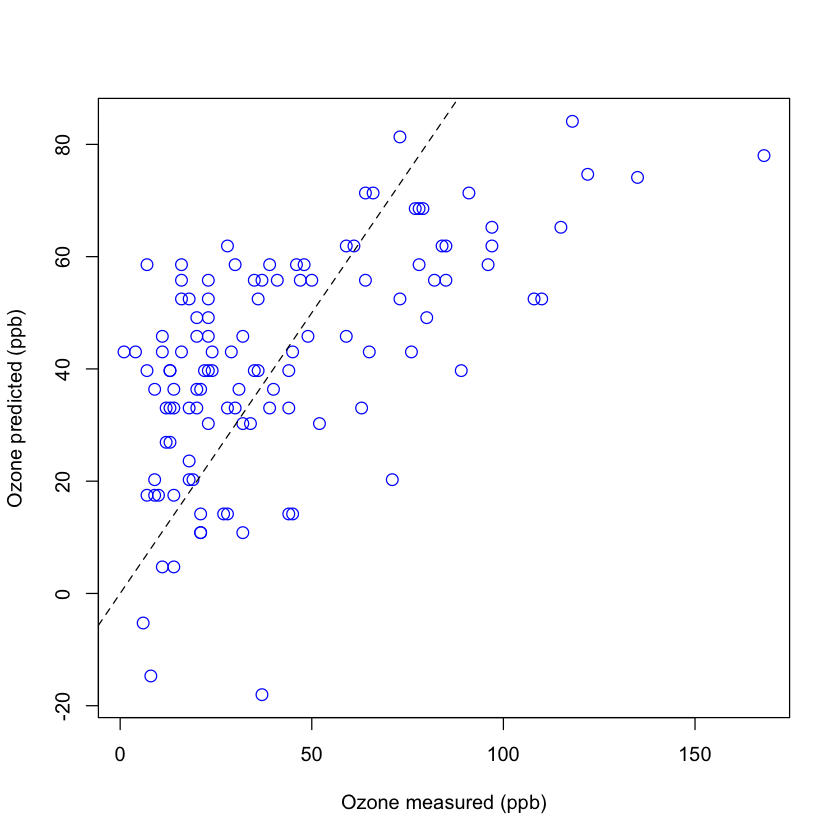

In [13]:
airquality2 <- cbind(na.omit(airquality[, c("Ozone", "Wind")]),
                     predicted = predict(fit))
# 1º gráfico: modelo real
plot(airquality2$Ozone, airquality2$predicted,
     xlab = "Ozone measured (ppb)",
     ylab = "Ozone predicted (ppb)",
     pch = 1, col = "blue", cex = 1.3)
abline(0, 1, lty = 2)

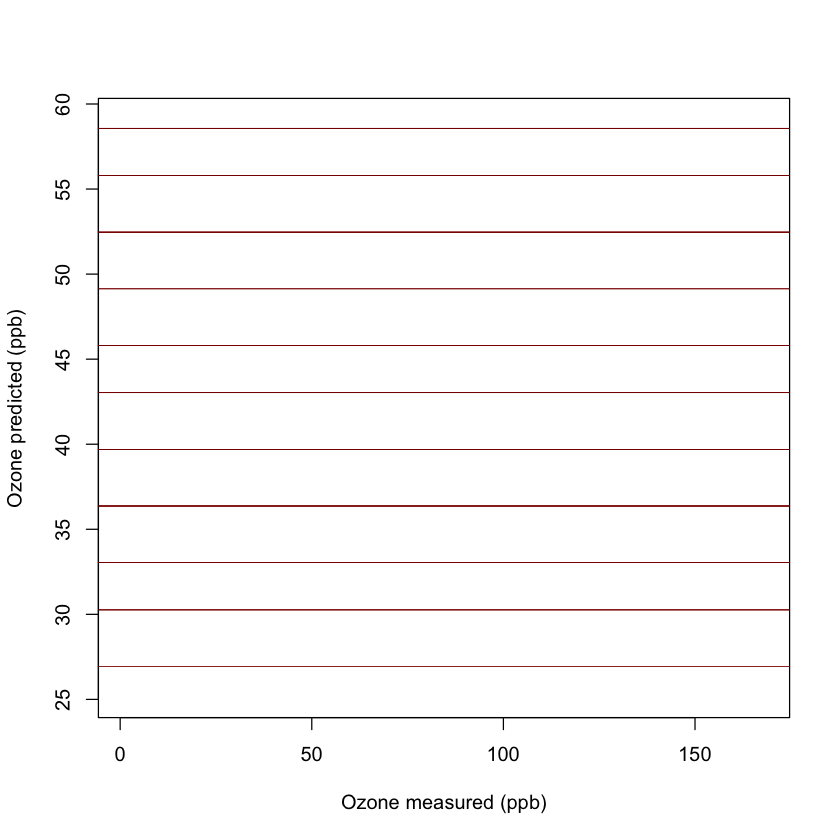

In [14]:
# Pra os missing data, o valor medido pode ser qualquer um.

mean_pred <- mean(airquality2$predicted)
plot(airquality2$Ozone, rep(mean_pred, nrow(airquality2)),
     xlab = "Ozone measured (ppb)",
     ylab = "Ozone predicted (ppb)",
     type = "n")  # não plota pontos inicialmente
for (i in seq_len(nrow(airquality2))) {
  abline(h = airquality2$predicted[i], col = "darkred", lwd = 0.5)
}

In [15]:
# Vamos agora tentar criar um modelo com mais uma variável
fit2 <- lm(Ozone ~ Wind + Solar.R, data = airquality)
naprint(na.action(fit2))

# NOTE! A amostra mudou!!!
# Podemos comparar os coeficientes de regressão dos dois modelos?
# Devemos atribuir as diferenças nos coeficientes a mudanças no modelo ou a
# mudanças na subamostra?

[1] "42 observations deleted due to missingness"

A abordagem padrão para lidar com dados ausentes é excluí-los.

Na literatura acadêmica:

A presença de dados ausentes muitas vezes não é declarada explicitamente no texto;

Métodos padrão, como a exclusão de casos completos (listwise deletion), são usados sem serem mencionados;

Tabelas diferentes são baseadas em tamanhos de amostra diferentes;

Métodos mais sofisticados são subutilizados.

In [16]:
# exemplo listwise deletion vs pairwise deletion

head(airquality)

airquality <- airquality[, sapply(airquality, is.numeric)]

,Ozone,Solar.R,Wind,Temp,Month,Day
,<int>,<int>,<dbl>,<int>,<int>,<int>
1,41,190,7.4,67,5,1
2,36,118,8.0,72,5,2
3,12,149,12.6,74,5,3
4,18,313,11.5,62,5,4
5,NA,NA,14.3,56,5,5
6,28,NA,14.9,66,5,6


In [17]:
# Covariância usando listwise deletion (remove linhas com qualquer NA)
# Listwise deletion (complete.obs):
# qualquer linha com pelo menos um NA é removida do cálculo de todas as variáveis.
cv <- cov(airquality, use = "complete.obs")
cv

,Ozone,Solar.R,Wind,Temp,Month,Day
Ozone,1107.290090,1056.583456,-72.511237,221.520721,7.0056511,-1.5036855
Solar.R,1056.583456,8308.742179,-41.244799,255.467649,-9.9476658,-45.8380835
Wind,-72.511237,-41.244799,12.657324,-16.857166,-1.0195577,1.5448894
Temp,221.520721,255.467649,-16.857166,90.820311,5.6724816,-8.0113022
Month,7.005651,-9.947666,-1.019558,5.672482,2.1710074,-0.1154791
Day,-1.503686,-45.838084,1.544889,-8.011302,-0.1154791,75.8152334


In [18]:
# Pairwise deletion (pairwise.complete.obs):
# cada par de variáveis usa todos os casos disponíveis para aquele par.

cv <- cov(airquality, use = "pairwise.complete.obs")
cv

,Ozone,Solar.R,Wind,Temp,Month,Day
Ozone,1088.200525,1056.583456,-70.9385307,218.521214,8.0089205,-3.8175412
Solar.R,1056.583456,8110.519414,-17.9459707,229.159754,-9.5222485,-119.0259802
Wind,-70.938531,-17.945971,12.4115385,-15.272136,-0.8897532,0.8488519
Temp,218.521214,229.159754,-15.2721362,89.591331,5.6439628,-10.9574303
Month,8.008921,-9.522248,-0.8897532,5.643963,2.0065359,-0.0999742
Day,-3.817541,-119.025980,0.8488519,-10.957430,-0.0999742,78.5797214


In [19]:
# mean imputation
# Multivariate Imputation by Chained Equations
install.packages("mice")  # instala
library("mice")            # carrega
imp <- mice(airquality, method = "mean", m = 1, maxit = 1)

also installing the dependencies ‘rbibutils’, ‘bit’, ‘prettyunits’, ‘Rdpack’, ‘bit64’, ‘progress’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘ucminf’, ‘numDeriv’, ‘clipr’, ‘vroom’, ‘tzdb’, ‘iterators’, ‘lme4’, ‘ordinal’, ‘forcats’, ‘hms’, ‘readr’, ‘tidyselect’, ‘foreach’, ‘shape’, ‘RcppEigen’, ‘pan’, ‘jomo’, ‘haven’, ‘broom’, ‘dplyr’, ‘glmnet’, ‘mitml’, ‘tidyr’





The downloaded binary packages are in
	/var/folders/_s/rczzsmpd4kl4kf77y1bwcf600000gn/T//Rtmpl9Ukpd/downloaded_packages



Attaching package: ‘mice’


The following object is masked from ‘package:stats’:

    filter


The following objects are masked from ‘package:base’:

    cbind, rbind





 iter imp variable
  1   1  Ozone  Solar.R


In [20]:
# desvio-padrao e correlação antes e depois da imputação.
# Carregar pacotes
library(mice)
library(ggplot2)

# Visualizar dados originais
summary(airquality$Ozone)
summary(airquality$Solar.R)

# Calcular estatísticas originais
sd_original_ozone <- sd(airquality$Ozone, na.rm = TRUE)
cor_original <- cor(airquality$Ozone, airquality$Solar.R, use = "pairwise.complete.obs")

cat("Desvio padrão original Ozone:", sd_original_ozone, "\n")
cat("Correlação original Ozone x Solar.R:", cor_original, "\n")

# Imputação pela média usando mice
imp <- mice(airquality, method = "mean", m = 1, maxit = 1)
completed_data <- complete(imp)

# Calcular estatísticas após imputação
sd_imputed_ozone <- sd(completed_data$Ozone)
cor_imputed <- cor(completed_data$Ozone, completed_data$Solar.R)

cat("Desvio padrão Ozone após imputação:", sd_imputed_ozone, "\n")
cat("Correlação Ozone x Solar.R após imputação:", cor_imputed, "\n")

# Plotar distribuição antes e depois
airquality$Type <- "Original"
completed_data$Type <- "Imputed"

combined <- rbind(
  data.frame(Ozone = airquality$Ozone, Type = airquality$Type),
  data.frame(Ozone = completed_data$Ozone, Type = completed_data$Type)
)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
   1.00   18.00   31.50   42.13   63.25  168.00      37 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
    7.0   115.8   205.0   185.9   258.8   334.0       7 

Desvio padrão original Ozone: 32.98788 
Correlação original Ozone x Solar.R: 0.3483417 

 iter imp variable
  1   1  Ozone  Solar.R
Desvio padrão Ozone após imputação: 28.69337 
Correlação Ozone x Solar.R após imputação: 0.3029695 


In [21]:
# Imputacao por regressão
fit <- lm(Ozone ~ Solar.R, data = airquality)
pred <- predict(fit, newdata = ic(airquality))

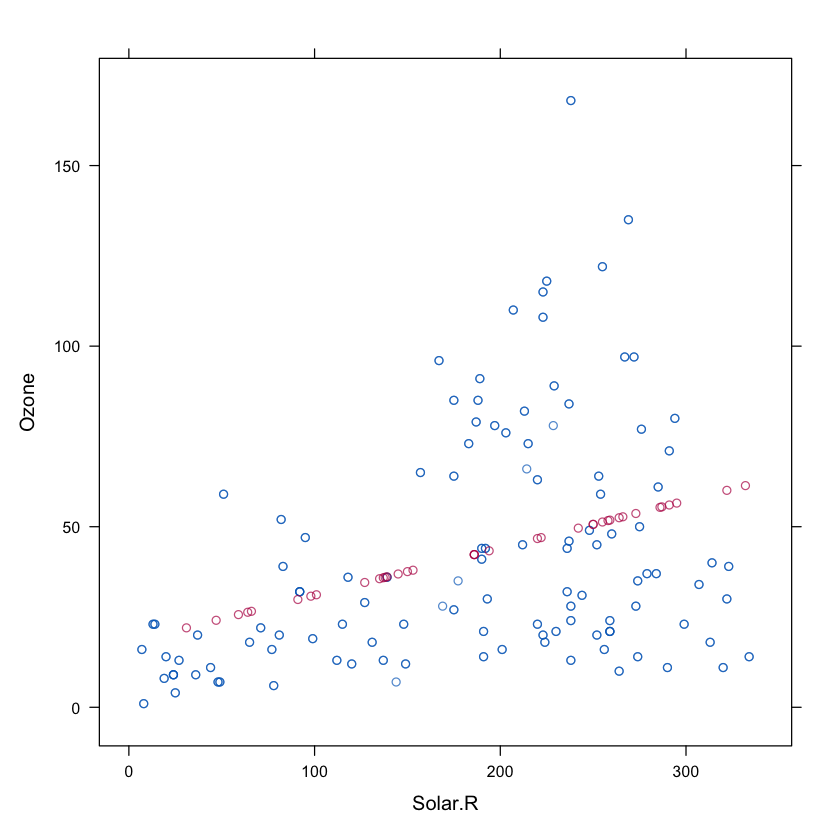

In [27]:
# Imputacao por regressão com mice

data <- airquality[, c("Ozone", "Solar.R")]
imp <- mice(data, method = "norm.predict", seed = 1,
           m = 1, print = FALSE)
xyplot(imp, Ozone ~ Solar.R)

In [23]:
# LOCF
airquality2 <- tidyr::fill(airquality, Ozone)